# 1. Business Understanding

### 1.1 Latar belakang masalah
Identifikasi varietas kacang kering dapat dilakukan berdasarkan karakteristik bentuk dan ukuran biji. Dataset Dry Bean berisi pengukuran morfologi dari beberapa varietas kacang yang diperoleh melalui proses pengolahan citra. Pengukuran tersebut dapat dimanfaatkan untuk membangun model yang memprediksi varietas kacang berdasarkan ciri-ciri numeriknya.

### 1.2 Rumusan masalah
1. Apakah 16 fitur morfologi dapat digunakan untuk membedakan tujuh varietas kacang kering?
2. Fitur morfologi apa yang paling berkontribusi terhadap proses klasifikasi?
3. Bagaimana perbandingan kinerja Support Vector Machine dan Random Forest pada dataset ini?

### 1.3 Tujuan
- Memahami karakteristik dan distribusi data Dry Bean.
- Melakukan pemeriksaan kualitas data, termasuk missing value, duplikat, tipe data, dan kandidat outlier.
- Menyeleksi fitur yang relevan menggunakan pendekatan korelasi pada data latih.
- Membandingkan model SVM dan Random Forest untuk klasifikasi tujuh kelas.
- Menentukan model terbaik berdasarkan hasil evaluasi pada data uji.

### 1.4 Metode dan alasan pemilihan
Proyek ini menggunakan **klasifikasi** karena variabel target `Class` berisi label kategori, bukan nilai numerik kontinu. Model yang digunakan:
- **SVM kernel linear:** sesuai materi Modul 6. SVM menggunakan batas pemisah (hyperplane), dan membutuhkan scaling karena sensitif terhadap skala fitur.
- **Random Forest:** sesuai materi Modul 7. Model ini menggabungkan sejumlah Decision Tree dan dapat memberikan nilai feature importance.

### 1.5 Metrik evaluasi
- **Accuracy:** proporsi seluruh prediksi yang benar.
- **Precision:** ketepatan prediksi untuk masing-masing kelas.
- **Recall:** kemampuan model menemukan anggota dari masing-masing kelas.
- **F1-score:** keseimbangan precision dan recall.
- **Macro F1-score:** rata-rata F1 setiap kelas dengan bobot sama; digunakan sebagai metrik utama agar kinerja pada setiap varietas diperhatikan.
- **Confusion Matrix:** memperlihatkan jumlah prediksi benar dan salah antar kelas.

### 1.6 Batasan proyek
Model hanya mempelajari tujuh varietas yang tersedia pada dataset. Dataset berisi fitur numerik hasil ekstraksi citra, bukan file gambar biji secara langsung. Hasil model tidak otomatis menjamin kinerja yang sama pada varietas atau kondisi pengambilan gambar di luar dataset.

# 2. Persiapan Environment dan Import Library

Library yang digunakan sesuai materi praktikum: pandas dan numpy untuk pengolahan data, matplotlib dan seaborn untuk visualisasi, serta scikit-learn untuk preprocessing, pembagian data, pemodelan, dan evaluasi.

Jalankan instalasi berikut satu kali apabila library belum tersedia.

In [33]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42
DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)

print('Library berhasil diimpor.')

Library berhasil diimpor.


# 3. Data Gathering

### 3.1 Sumber dan kredibilitas data
Dataset diperoleh dari **UCI Machine Learning Repository**.

- Nama: Dry Bean
- URL: https://archive.ics.uci.edu/dataset/602/dry+bean+dataset
- DOI: https://doi.org/10.24432/C50S4B
- Lisensi: Creative Commons Attribution 4.0 International (CC BY 4.0)
- Jumlah observasi menurut halaman UCI: 13.611
- Fitur: 16 fitur morfologi numerik
- Target: `Class`, berisi tujuh varietas kacang
- Catatan kualitas menurut UCI: tidak terdapat missing value pada dataset asli.

Dataset berasal dari citra 13.611 biji kacang yang diproses menggunakan sistem computer vision. Fitur yang diperoleh mencakup ukuran dan karakteristik bentuk biji.

### 3.2 Memuat dataset
Kode akan mencari file Excel lokal terlebih dahulu. Jika file belum tersedia, dataset diambil melalui paket `ucimlrepo` dari UCI. Dengan cara ini notebook tetap dapat dijalankan tanpa perlu mengubah kode pemuatan data, selama koneksi internet tersedia.

In [34]:
# Opsi 1: gunakan file Excel lokal jika sudah diunduh dari UCI.
local_excel_candidates = [
    DATA_DIR / 'Dry_Bean_Dataset.xlsx',
    Path('Dry_Bean_Dataset.xlsx')
]
local_excel = next((p for p in local_excel_candidates if p.exists()), None)

if local_excel is not None:
    print(f'Memuat dataset dari file lokal: {local_excel}')
    df_raw = pd.read_excel(local_excel)
else:
    print('File Excel lokal tidak ditemukan. Mengambil dataset dari UCI...')
    dry_bean = fetch_ucirepo(id=602)
    df_raw = pd.concat(
        [dry_bean.data.features, dry_bean.data.targets],
        axis=1
    )

# Merapikan spasi pada nama kolom.
df_raw.columns = df_raw.columns.astype(str).str.strip()

# Menyamakan nama target jika sumber menuliskannya dengan variasi huruf.
class_columns = [col for col in df_raw.columns if col.lower() == 'class']
if not class_columns:
    raise ValueError('Kolom target Class tidak ditemukan pada dataset.')
if class_columns[0] != 'Class':
    df_raw = df_raw.rename(columns={class_columns[0]: 'Class'})

# Simpan salinan data mentah ke folder proyek agar dapat disertakan di repository.
raw_csv_path = DATA_DIR / 'dry_bean_raw.csv'
df_raw.to_csv(raw_csv_path, index=False)

print('Dataset berhasil dimuat.')
print('Lokasi salinan data mentah:', raw_csv_path)
print('Ukuran dataset:', df_raw.shape)

Memuat dataset dari file lokal: Dry_Bean_Dataset.xlsx
Dataset berhasil dimuat.
Lokasi salinan data mentah: data\dry_bean_raw.csv
Ukuran dataset: (13611, 17)


In [35]:
print('Lima data pertama:')
display(df_raw.head())

print('\nInformasi dataset:')
df_raw.info()

print('\nStatistik deskriptif:')
display(df_raw.describe(include='all').T)

print('\nNama kolom:')
print(df_raw.columns.tolist())

Lima data pertama:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER



Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  objec

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Area,13611.0,NaN,NaN,NaN,53048.284549,29324.095717,20420.0,36328.0,44652.0,61332.0,254616.0
Perimeter,13611.0,NaN,NaN,NaN,855.283459,214.289696,524.736,703.5235,794.941,977.213,1985.37
MajorAxisLength,13611.0,NaN,NaN,NaN,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,NaN,NaN,NaN,202.270714,44.970091,122.512653,175.84817,192.431733,217.031741,460.198497
AspectRation,13611.0,NaN,NaN,NaN,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,NaN,NaN,NaN,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,NaN,NaN,NaN,53768.200206,29774.915817,20684.0,36714.5,45178.0,62294.0,263261.0
EquivDiameter,13611.0,NaN,NaN,NaN,253.06422,59.17712,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,NaN,NaN,NaN,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,NaN,NaN,NaN,0.987143,0.00466,0.919246,0.98567,0.988283,0.990013,0.994677



Nama kolom:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']


### 3.3 Pengertian fitur
Berikut penjelasan umum variabel yang tersedia pada dataset. Nama kolom di file sumber dapat memiliki variasi ejaan, misalnya `AspectRation` atau `AspectRatio`; kode tetap menggunakan nama kolom asli yang dimuat.

| Fitur | Keterangan |
|---|---|
| Area | Luas area biji berdasarkan jumlah piksel di dalam batas biji |
| Perimeter | Keliling atau panjang batas biji |
| MajorAxisLength | Panjang sumbu utama biji |
| MinorAxisLength | Panjang sumbu minor biji |
| AspectRatio / AspectRation | Perbandingan sumbu utama dan sumbu minor |
| Eccentricity | Tingkat ke-elips-an bentuk biji |
| ConvexArea | Luas poligon convex terkecil yang mencakup biji |
| EquivDiameter | Diameter lingkaran dengan luas setara luas biji |
| Extent | Rasio area biji terhadap area bounding box |
| Solidity | Rasio area biji terhadap area convex |
| roundness | Ukuran kebulatan biji |
| Compactness | Ukuran kekompakan atau kebulatan bentuk |
| ShapeFactor1–4 | Empat ukuran tambahan yang menggambarkan karakteristik bentuk |
| Class | Label varietas kacang yang menjadi target klasifikasi |

Target terdiri dari tujuh kelas: Seker, Barbunya, Bombay, Cali, Dermason, Horoz, dan Sira.

# 4. Exploratory Data Analysis (EDA)

EDA dilakukan sebelum pembersihan untuk memahami kondisi awal data. Analisis mencakup struktur data, statistik deskriptif, distribusi kelas, distribusi fitur numerik, hubungan antar fitur, dan kandidat outlier. Setiap visualisasi perlu dibaca bersama output aktual setelah notebook dijalankan.

In [36]:
# Memisahkan nama fitur dan target.
feature_cols_raw = [col for col in df_raw.columns if col != 'Class']

print('Jumlah baris:', len(df_raw))
print('Jumlah fitur:', len(feature_cols_raw))
print('Jumlah kelas target:', df_raw['Class'].nunique())
print('\nJumlah data per kelas:')
display(df_raw['Class'].value_counts().rename('Jumlah').to_frame())

print('\nPersentase data per kelas (%):')
display((df_raw['Class'].value_counts(normalize=True) * 100).round(2).rename('Persentase').to_frame())

Jumlah baris: 13611
Jumlah fitur: 16
Jumlah kelas target: 7

Jumlah data per kelas:


,Jumlah
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1928
CALI,1630
BARBUNYA,1322
BOMBAY,522



Persentase data per kelas (%):


,Persentase
Class,
DERMASON,26.05
SIRA,19.37
SEKER,14.89
HOROZ,14.17
CALI,11.98
BARBUNYA,9.71
BOMBAY,3.84


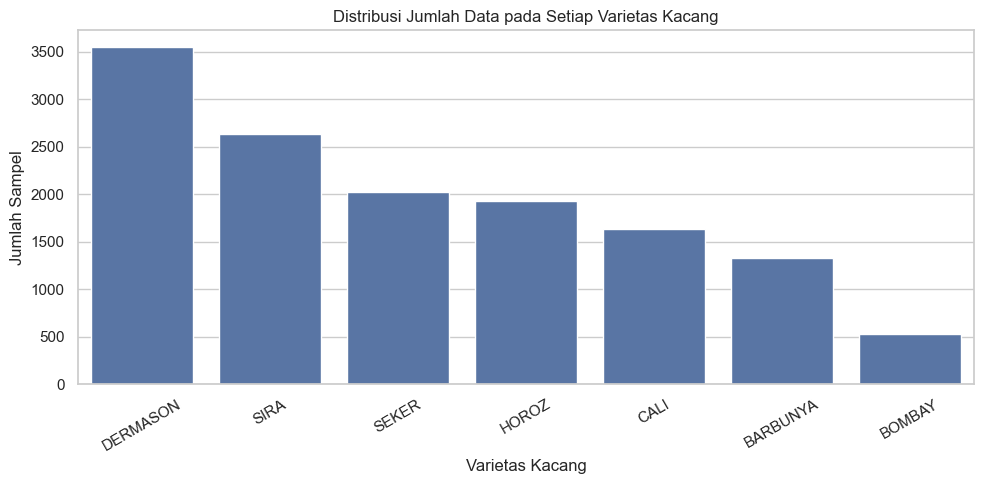

In [37]:
# Visualisasi distribusi kelas.
plt.figure(figsize=(10, 5))
order_class = df_raw['Class'].value_counts().index
sns.countplot(data=df_raw, x='Class', order=order_class)
plt.title('Distribusi Jumlah Data pada Setiap Varietas Kacang')
plt.xlabel('Varietas Kacang')
plt.ylabel('Jumlah Sampel')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [38]:
# Statistik deskriptif fitur numerik.
eda_numeric = df_raw[feature_cols_raw].describe().T
eda_numeric['skewness'] = df_raw[feature_cols_raw].skew(numeric_only=True)
display(eda_numeric.sort_values('std', ascending=False))

,count,mean,std,min,25%,50%,75%,max,skewness
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000,2.941821
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000,2.952931
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000,1.626124
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153,1.357815
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358,1.948958
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497,2.238211
AspectRation,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306,0.582573
ShapeFactor3,13611.0,0.643590,0.098996,0.410339,0.581359,0.642044,0.696006,0.974767,0.242481
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423,-1.062824
Compactness,13611.0,0.799864,0.061713,0.640577,0.762469,0.801277,0.834270,0.987303,0.037115


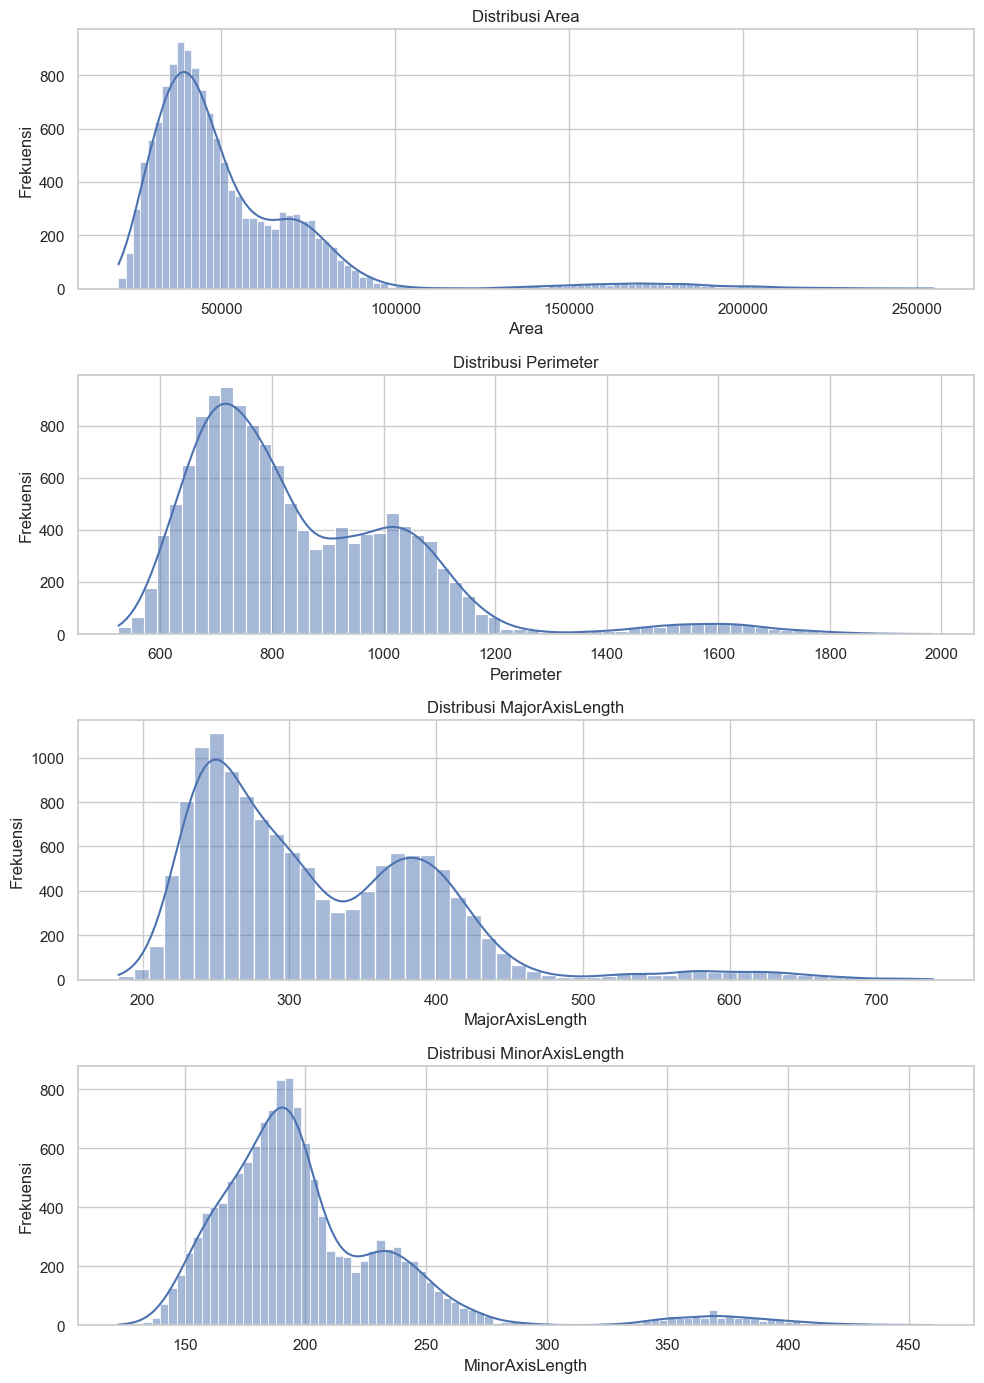

In [39]:
# Histogram untuk beberapa fitur utama.
selected_for_hist = [
    col for col in ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength']
    if col in df_raw.columns
]

fig, axes = plt.subplots(len(selected_for_hist), 1, figsize=(10, 3.5 * len(selected_for_hist)))
if len(selected_for_hist) == 1:
    axes = [axes]

for ax, col in zip(axes, selected_for_hist):
    sns.histplot(data=df_raw, x=col, kde=True, ax=ax)
    ax.set_title(f'Distribusi {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

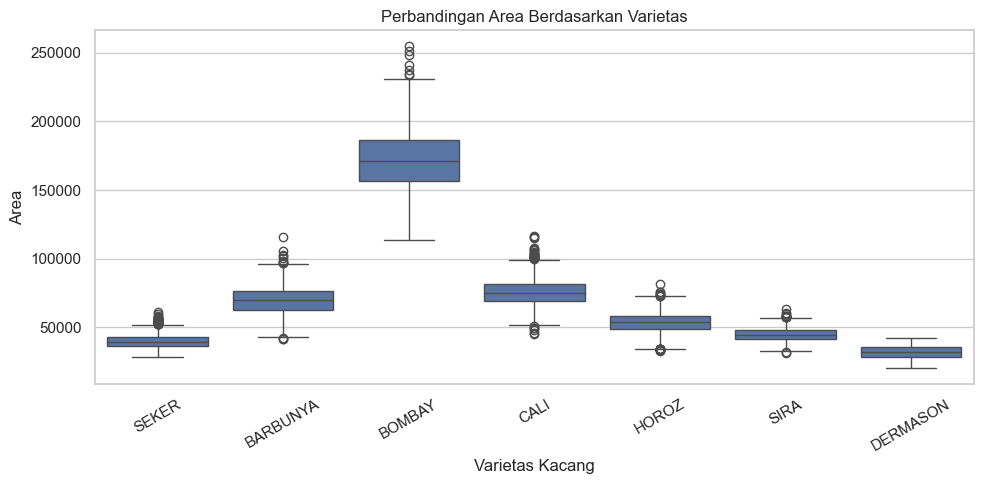

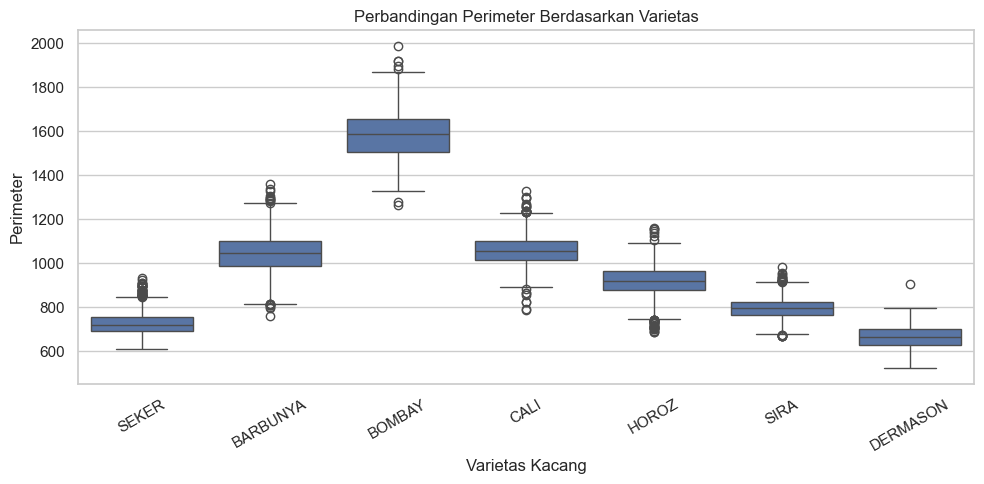

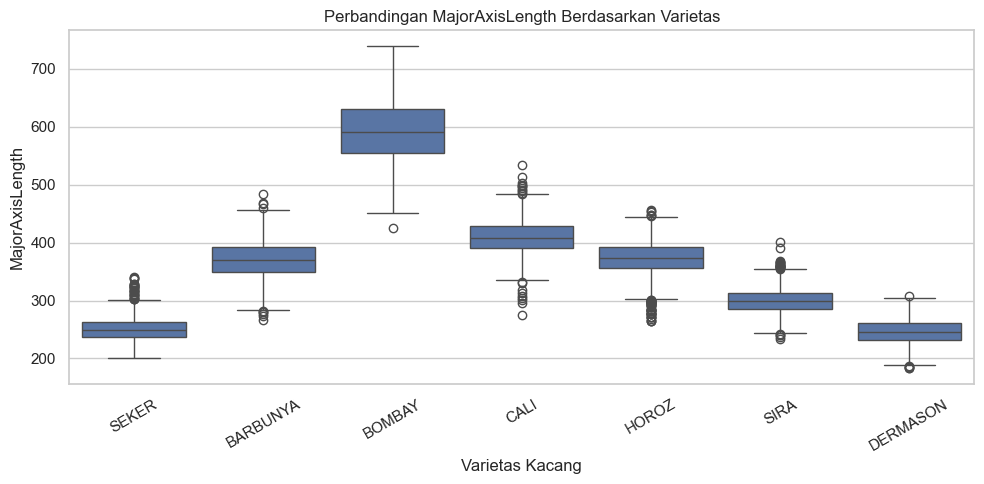

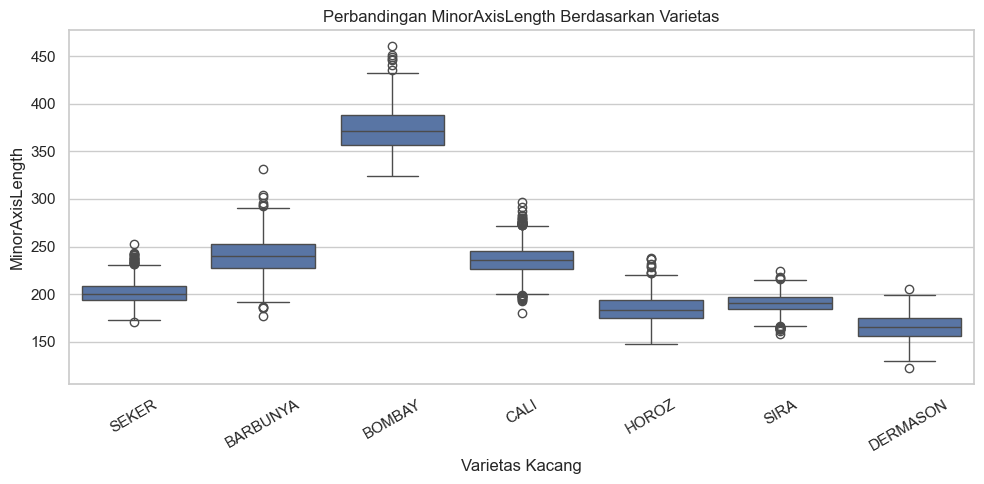

In [40]:
# Boxplot per kelas untuk melihat perbedaan sebaran dan kandidat nilai ekstrem.
box_features = [
    col for col in ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength']
    if col in df_raw.columns
]

for col in box_features:
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=df_raw, x='Class', y=col)
    plt.title(f'Perbandingan {col} Berdasarkan Varietas')
    plt.xlabel('Varietas Kacang')
    plt.ylabel(col)
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

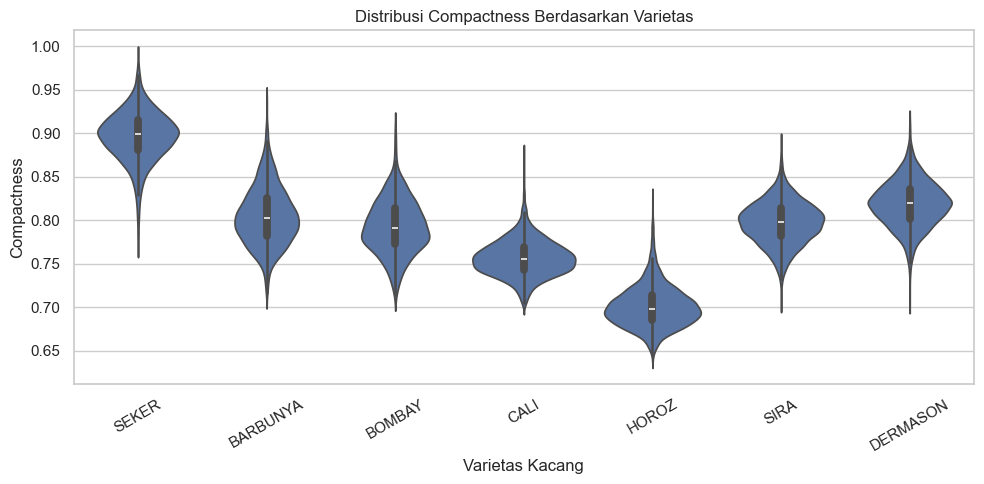

In [41]:
# Violin plot untuk melihat bentuk distribusi fitur pada masing-masing kelas.
violin_feature = 'Compactness' if 'Compactness' in df_raw.columns else feature_cols_raw[-1]
plt.figure(figsize=(10, 5))
sns.violinplot(data=df_raw, x='Class', y=violin_feature)
plt.title(f'Distribusi {violin_feature} Berdasarkan Varietas')
plt.xlabel('Varietas Kacang')
plt.ylabel(violin_feature)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

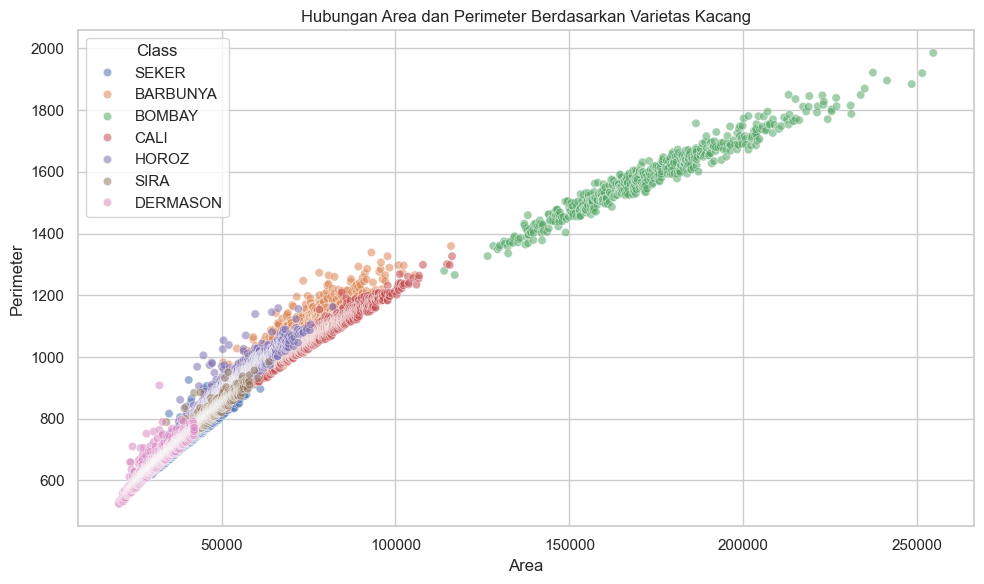

In [42]:
# Scatter plot untuk melihat hubungan dua fitur ukuran.
if {'Area', 'Perimeter'}.issubset(df_raw.columns):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(data=df_raw, x='Area', y='Perimeter', hue='Class', alpha=0.55)
    plt.title('Hubungan Area dan Perimeter Berdasarkan Varietas Kacang')
    plt.tight_layout()
    plt.show()

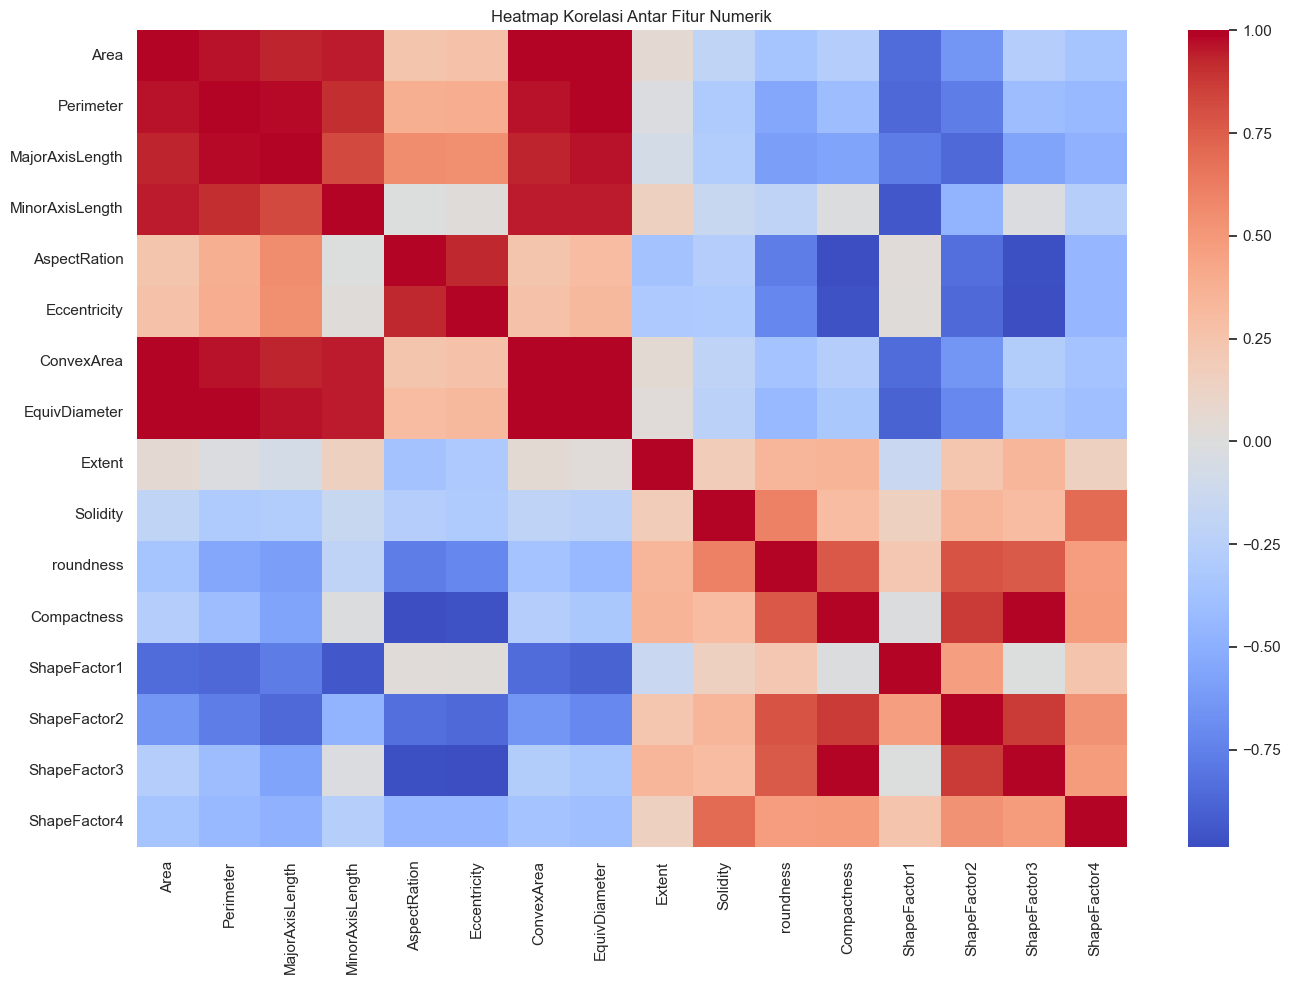

In [43]:
# Heatmap korelasi antar fitur numerik.
corr_eda = df_raw[feature_cols_raw].corr(numeric_only=True)
plt.figure(figsize=(14, 10))
sns.heatmap(corr_eda, cmap='coolwarm', center=0, annot=False)
plt.title('Heatmap Korelasi Antar Fitur Numerik')
plt.tight_layout()
plt.show()

### 4.1 Panduan interpretasi hasil EDA
Tuliskan interpretasi berdasarkan grafik dan angka yang benar-benar muncul saat notebook dijalankan. Jangan hanya menjelaskan bentuk grafik.

Hal yang perlu dijawab:
1. Kelas kacang apa yang memiliki jumlah sampel paling banyak dan paling sedikit?
2. Bagaimana rentang dan sebaran fitur ukuran seperti `Area` dan `Perimeter`?
3. Apakah beberapa kelas tampak memiliki pola ukuran yang berbeda?
4. Pasangan fitur apa yang mempunyai korelasi positif atau negatif paling kuat?
5. Apakah boxplot menunjukkan kandidat outlier? Apakah nilai tersebut masuk akal sebagai variasi ukuran biji?

**Catatan:** korelasi yang tinggi antar fitur menunjukkan adanya informasi yang mirip (redundansi), tetapi tidak otomatis berarti salah satu fitur harus dibuang tanpa alasan.

# 5. Data Cleaning

Tahap ini mengikuti materi Modul 2: pemeriksaan missing value, duplikat, validasi tipe data, dan penanganan data. UCI menyatakan dataset aslinya tidak memiliki missing value, tetapi pemeriksaan tetap dilakukan agar kondisi file yang digunakan dapat dibuktikan.

Baris duplikat yang identik diperiksa dan dihapus agar sampel yang sama tidak berulang. Kandidat outlier tidak langsung dihapus karena nilai ekstrem dapat merupakan variasi morfologi kacang yang valid.

In [44]:
df_clean = df_raw.copy()

# Validasi tipe data fitur: setiap fitur morfologi harus berupa angka.
feature_cols = [col for col in df_clean.columns if col != 'Class']
for col in feature_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

# Rapikan target.
df_clean['Class'] = df_clean['Class'].astype('string').str.strip()

print('Tipe data setelah validasi:')
print(df_clean.dtypes)

print('\nJumlah missing value per kolom:')
missing_before = df_clean.isnull().sum().sort_values(ascending=False)
display(missing_before.to_frame('Missing Value'))
print('Total missing value:', int(df_clean.isnull().sum().sum()))

print('\nJumlah baris duplikat sebelum dihapus:', int(df_clean.duplicated().sum()))

Tipe data setelah validasi:
Area                        int64
Perimeter                 float64
MajorAxisLength           float64
MinorAxisLength           float64
AspectRation              float64
Eccentricity              float64
ConvexArea                  int64
EquivDiameter             float64
Extent                    float64
Solidity                  float64
roundness                 float64
Compactness               float64
ShapeFactor1              float64
ShapeFactor2              float64
ShapeFactor3              float64
ShapeFactor4              float64
Class              string[python]
dtype: object

Jumlah missing value per kolom:


,Missing Value
Area,0
Perimeter,0
MajorAxisLength,0
MinorAxisLength,0
AspectRation,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Solidity,0


Total missing value: 0

Jumlah baris duplikat sebelum dihapus: 68


In [45]:
# Hapus baris yang tidak memiliki label target.
rows_before = len(df_clean)
df_clean = df_clean.dropna(subset=['Class']).copy()
print('Baris tanpa label Class yang dihapus:', rows_before - len(df_clean))

# Hapus duplikat identik, jika ada.
duplicates_before = int(df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print('Duplikat identik yang dihapus:', duplicates_before)
print('Jumlah baris setelah cleaning:', len(df_clean))
print('Duplikat tersisa:', int(df_clean.duplicated().sum()))

print('\nMissing value setelah pembersihan duplikat:')
display(df_clean.isnull().sum().to_frame('Missing Value'))

Baris tanpa label Class yang dihapus: 0
Duplikat identik yang dihapus: 68
Jumlah baris setelah cleaning: 13543
Duplikat tersisa: 0

Missing value setelah pembersihan duplikat:


,Missing Value
Area,0
Perimeter,0
MajorAxisLength,0
MinorAxisLength,0
AspectRation,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Solidity,0


In [46]:
# Hitung kandidat outlier berdasarkan aturan IQR.
# Outlier dihitung untuk pemeriksaan, tetapi tidak langsung dihapus.
outlier_summary = []
for col in feature_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    count_outlier = ((df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)).sum()
    outlier_summary.append({
        'Fitur': col,
        'Batas Bawah IQR': lower_bound,
        'Batas Atas IQR': upper_bound,
        'Jumlah Kandidat Outlier': int(count_outlier),
        'Persentase (%)': round(count_outlier / len(df_clean) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary).sort_values(
    'Jumlah Kandidat Outlier', ascending=False
)
display(outlier_df)

print('Jumlah data sebelum dan sesudah cleaning:')
print('Sebelum:', len(df_raw))
print('Sesudah:', len(df_clean))

,Fitur,Batas Bawah IQR,Batas Atas IQR,Jumlah Kandidat Outlier,Persentase (%)
5,Eccentricity,0.573352,0.951463,833,6.15
9,Solidity,0.979168,0.996529,774,5.72
15,ShapeFactor4,0.987463,1.004149,760,5.61
3,MinorAxisLength,113.847787,279.283973,567,4.19
0,Area,-1366.750000,99031.250000,551,4.07
6,ConvexArea,-1857.500000,100890.500000,549,4.05
12,ShapeFactor1,0.003827,0.009336,533,3.94
7,EquivDiameter,117.992667,376.500961,526,3.88
1,Perimeter,292.355250,1388.021250,500,3.69
4,AspectRation,1.020780,2.113797,485,3.58


Jumlah data sebelum dan sesudah cleaning:
Sebelum: 13611
Sesudah: 13543


### 5.1 Keputusan cleaning
- **Missing value:** ikuti hasil pemeriksaan. Jika data asli memang tidak memiliki nilai kosong, tidak perlu melakukan imputasi.
- **Duplikat:** baris yang identik dihapus, jika ditemukan.
- **Tipe data:** semua fitur morfologi dikonversi menjadi numerik; `Class` dipertahankan sebagai kategori teks.
- **Outlier:** tetap dipertahankan pada tahap ini. Metode IQR hanya menandai kandidat outlier, bukan membuktikan bahwa nilainya salah. Penghapusan baru layak dilakukan apabila ada bukti kesalahan pencatatan atau pengukuran.

Jika terdapat nilai fitur yang kosong setelah konversi tipe data, notebook akan menanganinya dengan median di dalam pipeline model. Dengan demikian, median dihitung dari data latih saja dan tidak mengambil informasi dari data uji.

In [47]:
# Simpan dataset bersih sebelum pemodelan.
clean_csv_path = DATA_DIR / 'dry_bean_cleaned.csv'
df_clean.to_csv(clean_csv_path, index=False)

print('Dataset bersih disimpan pada:', clean_csv_path)
print('Ukuran dataset bersih:', df_clean.shape)
display(df_clean.head())

Dataset bersih disimpan pada: data\dry_bean_cleaned.csv
Ukuran dataset bersih: (13543, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


# 6. Preprocessing dan Feature Engineering

### 6.1 Memisahkan fitur dan target
Kolom `Class` merupakan target kategorikal. Fitur lainnya sudah berupa numerik, sehingga tidak memerlukan One-Hot Encoding. LabelEncoder digunakan untuk mengubah label target menjadi angka agar pemetaan kelas lebih mudah dikelola oleh kode evaluasi.

### 6.2 Pembagian data
Data dibagi menjadi 80% data latih dan 20% data uji menggunakan `stratify` agar proporsi tujuh kelas tetap terjaga. Pemisahan dilakukan sebelum feature selection dan scaling untuk mencegah data leakage.

### 6.3 Binning (untuk analisis)
Binning pada fitur `Area` digunakan sebagai fitur bantu untuk analisis deskriptif ukuran biji. Kolom kategori ini tidak digunakan sebagai input model, karena model utama menggunakan fitur morfologi numerik asli.

Distribusi kategori Area:


Class,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
Area_Category,,,,,,,
Kecil,0,0,0,3233,50,971,261
Sedang,71,0,8,313,815,1029,2277
Besar,1251,522,1622,0,995,27,98


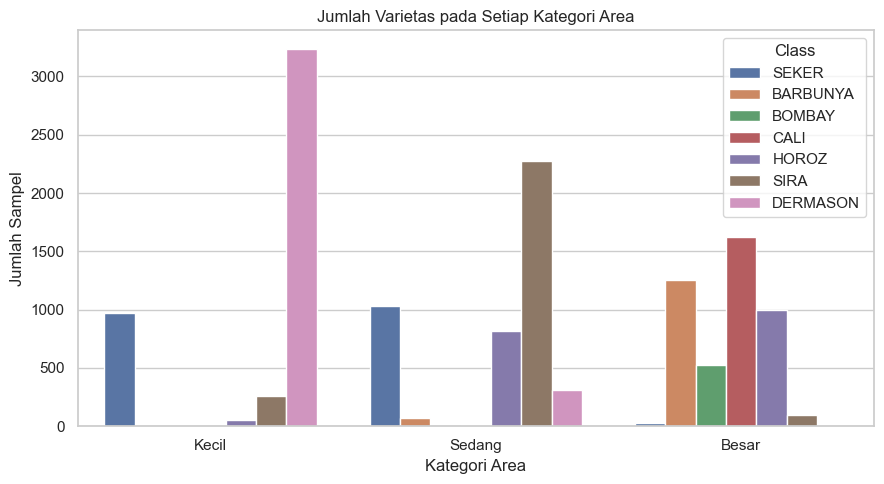

In [48]:
# Binning Area untuk membantu analisis deskriptif.
if 'Area' in df_clean.columns:
    df_clean['Area_Category'] = pd.qcut(
        df_clean['Area'],
        q=3,
        labels=['Kecil', 'Sedang', 'Besar'],
        duplicates='drop'
    )
    print('Distribusi kategori Area:')
    display(pd.crosstab(df_clean['Area_Category'], df_clean['Class']))

    plt.figure(figsize=(9, 5))
    sns.countplot(data=df_clean, x='Area_Category', hue='Class')
    plt.title('Jumlah Varietas pada Setiap Kategori Area')
    plt.xlabel('Kategori Area')
    plt.ylabel('Jumlah Sampel')
    plt.tight_layout()
    plt.show()

In [49]:
# Target encoding.
X = df_clean[feature_cols].copy()
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df_clean['Class'])

class_names = label_encoder.classes_
print('Pemetaan label kelas:')
for numeric_label, class_name in enumerate(class_names):
    print(f'{numeric_label} = {class_name}')

# Split 80% training dan 20% testing, dengan proporsi kelas terjaga.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print('\nUkuran data:')
print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train.shape)
print('y_test :', y_test.shape)

Pemetaan label kelas:
0 = BARBUNYA
1 = BOMBAY
2 = CALI
3 = DERMASON
4 = HOROZ
5 = SEKER
6 = SIRA

Ukuran data:
X_train: (10834, 16)
X_test : (2709, 16)
y_train: (10834,)
y_test : (2709,)


In [50]:
# Periksa proporsi kelas sebelum dan sesudah pembagian.
train_distribution = pd.Series(label_encoder.inverse_transform(y_train)).value_counts(normalize=True)
test_distribution = pd.Series(label_encoder.inverse_transform(y_test)).value_counts(normalize=True)
distribution_comparison = pd.DataFrame({
    'Training (%)': (train_distribution * 100).round(2),
    'Testing (%)': (test_distribution * 100).round(2)
}).fillna(0)
display(distribution_comparison)

,Training (%),Testing (%)
DERMASON,26.19,26.17
SIRA,19.47,19.45
SEKER,14.96,14.99
HOROZ,13.73,13.73
CALI,12.04,12.03
BARBUNYA,9.76,9.78
BOMBAY,3.86,3.84


# 7. Feature Selection dengan Korelasi

Materi Modul 3 menggunakan analisis korelasi sebagai metode filter untuk melihat hubungan antar fitur dan membantu memilih fitur yang relevan. Modul 6 juga menekankan bahwa pemilihan fitur harus dilakukan berdasarkan data latih saja agar informasi target pada data uji tidak ikut memengaruhi proses pelatihan.

Pada proyek multiclass ini, label target dibuat menjadi indikator one-vs-rest (satu kelas dibandingkan semua kelas lain). Untuk setiap fitur dihitung korelasi absolut terhadap setiap indikator kelas, kemudian digunakan korelasi absolut tertinggi sebagai skor ringkas fitur. Pendekatan ini menghindari anggapan bahwa kode angka kelas memiliki urutan matematis.

Dipilih maksimal 12 fitur teratas untuk pemodelan. Jumlah ini merupakan keputusan analisis proyek dan dapat diubah dengan alasan yang jelas.

,Feature,Max Absolute One-vs-Rest Correlation
0,Area,0.821241
6,ConvexArea,0.819621
3,MinorAxisLength,0.765928
5,Eccentricity,0.756515
7,EquivDiameter,0.729549
4,AspectRation,0.724722
14,ShapeFactor3,0.684144
1,Perimeter,0.682242
11,Compactness,0.658831
2,MajorAxisLength,0.637228


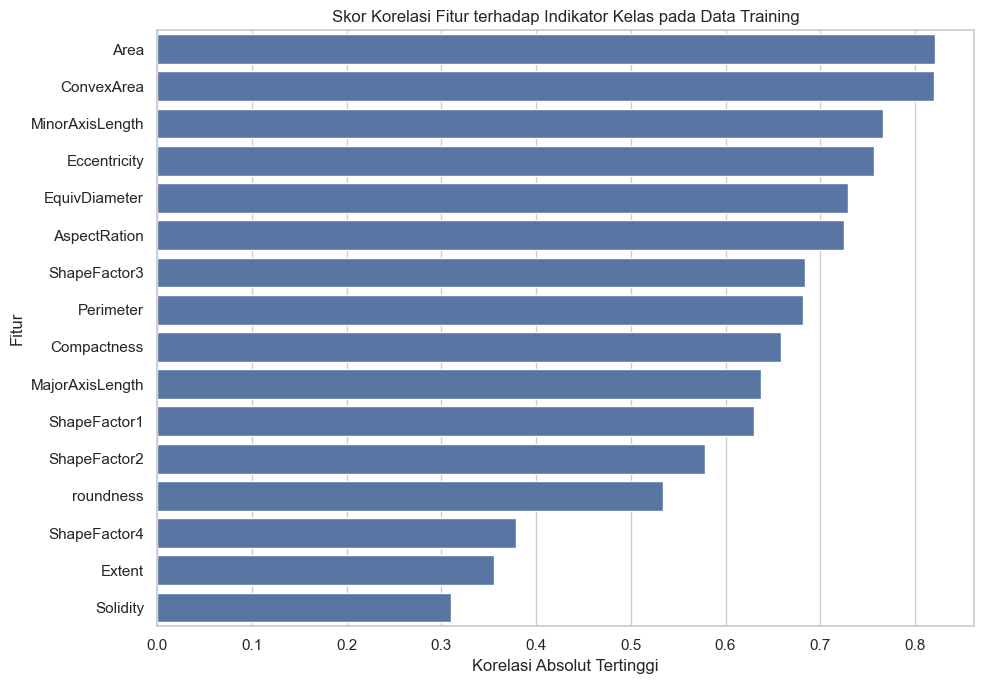

In [51]:
# Mengubah target training menjadi indikator biner untuk setiap kelas.
y_train_series = pd.Series(y_train, index=X_train.index, name='Class_encoded')
y_train_onehot = pd.get_dummies(y_train_series.astype(str))

feature_scores = {}
for col in X_train.columns:
    correlations = []
    for class_col in y_train_onehot.columns:
        corr_value = X_train[col].corr(y_train_onehot[class_col].astype(float))
        if pd.notna(corr_value):
            correlations.append(abs(corr_value))
    feature_scores[col] = max(correlations) if correlations else 0.0

feature_score_df = pd.DataFrame({
    'Feature': list(feature_scores.keys()),
    'Max Absolute One-vs-Rest Correlation': list(feature_scores.values())
}).sort_values('Max Absolute One-vs-Rest Correlation', ascending=False)

display(feature_score_df)

plt.figure(figsize=(10, 7))
sns.barplot(
    data=feature_score_df,
    x='Max Absolute One-vs-Rest Correlation',
    y='Feature'
)
plt.title('Skor Korelasi Fitur terhadap Indikator Kelas pada Data Training')
plt.xlabel('Korelasi Absolut Tertinggi')
plt.ylabel('Fitur')
plt.tight_layout()
plt.show()

In [52]:
# Pilih maksimal 12 fitur dengan skor korelasi tertinggi.
TOP_N_FEATURES = min(12, len(feature_score_df))
selected_features = feature_score_df.head(TOP_N_FEATURES)['Feature'].tolist()

print(f'Jumlah fitur awal: {len(feature_cols)}')
print(f'Jumlah fitur terpilih: {len(selected_features)}')
print('Fitur terpilih:')
print(selected_features)

X_train_selected = X_train[selected_features].copy()
X_test_selected = X_test[selected_features].copy()

print('\nUkuran data setelah feature selection:')
print('Training:', X_train_selected.shape)
print('Testing :', X_test_selected.shape)

Jumlah fitur awal: 16
Jumlah fitur terpilih: 12
Fitur terpilih:
['Area', 'ConvexArea', 'MinorAxisLength', 'Eccentricity', 'EquivDiameter', 'AspectRation', 'ShapeFactor3', 'Perimeter', 'Compactness', 'MajorAxisLength', 'ShapeFactor1', 'ShapeFactor2']

Ukuran data setelah feature selection:
Training: (10834, 12)
Testing : (2709, 12)


### 7.1 Alasan pemilihan fitur
Fitur dipilih berdasarkan skor korelasi absolut tertinggi terhadap indikator masing-masing kelas, dan perhitungan hanya menggunakan data training. Cara ini merupakan pendekatan filter berbasis korelasi. Seleksi fitur tidak menjamin semua fitur yang dibuang tidak berguna; karena itu, hasil evaluasi model dan feature importance tetap perlu diperhatikan.

### 7.2 Scaling
SVM sensitif terhadap skala karena menggunakan jarak dan margin dalam menentukan batas pemisah. Oleh karena itu, StandardScaler diletakkan di dalam Pipeline SVM. Random Forest berbasis pohon keputusan dan tidak memerlukan scaling fitur, sesuai penjelasan Modul 7.

Scaler dan imputasi hanya akan dipelajari dari data training karena berada dalam pipeline yang di-fit pada data training.

# 8. Modelling

Dua pendekatan yang digunakan mengikuti materi praktikum:

1. **SVM linear** dengan StandardScaler dalam Pipeline.
2. **Random Forest** dengan pengaturan hyperparameter sederhana.

Untuk Random Forest, beberapa kombinasi `n_estimators` dan `max_depth` dibandingkan menggunakan validation set yang diambil dari data training. Data testing tetap disimpan untuk evaluasi akhir dan tidak digunakan dalam pemilihan parameter.

In [53]:
# Membagi sebagian data training untuk validasi hyperparameter Random Forest.
X_train_fit, X_valid, y_train_fit, y_valid = train_test_split(
    X_train_selected,
    y_train,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train
)

rf_configurations = [
    {'n_estimators': 100, 'max_depth': 5, 'criterion': 'gini'},
    {'n_estimators': 100, 'max_depth': 10, 'criterion': 'gini'},
    {'n_estimators': 200, 'max_depth': None, 'criterion': 'gini'}
]

rf_tuning_results = []

for config in rf_configurations:
    rf_validation_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', RandomForestClassifier(
            n_estimators=config['n_estimators'],
            max_depth=config['max_depth'],
            criterion=config['criterion'],
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])

    rf_validation_pipeline.fit(X_train_fit, y_train_fit)
    y_valid_pred = rf_validation_pipeline.predict(X_valid)
    valid_macro_f1 = f1_score(y_valid, y_valid_pred, average='macro')

    rf_tuning_results.append({
        **config,
        'Validation Macro F1': valid_macro_f1
    })

rf_tuning_df = pd.DataFrame(rf_tuning_results).sort_values(
    'Validation Macro F1', ascending=False
).reset_index(drop=True)

display(rf_tuning_df)

best_rf_config_row = rf_tuning_df.iloc[0]
best_rf_config = {
    'n_estimators': int(best_rf_config_row['n_estimators']),
    'max_depth': None if pd.isna(best_rf_config_row['max_depth']) else int(best_rf_config_row['max_depth']),
    'criterion': str(best_rf_config_row['criterion'])
}
print('Konfigurasi Random Forest terbaik berdasarkan validation set:')
print(best_rf_config)

,n_estimators,max_depth,criterion,Validation Macro F1
0,200,NaN,gini,0.917047
1,100,10.0,gini,0.905664
2,100,5.0,gini,0.889944


Konfigurasi Random Forest terbaik berdasarkan validation set:
{'n_estimators': 200, 'max_depth': None, 'criterion': 'gini'}


In [54]:
# Model 1: SVM linear sesuai alur Modul 6.
svm_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', SVC(kernel='linear', C=1.0))
])

svm_model.fit(X_train_selected, y_train)
print('Model SVM berhasil dilatih.')

Model SVM berhasil dilatih.


In [55]:
# Parameter terbaik dari validation set digunakan untuk melatih ulang model dengan seluruh data training.
rf_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', RandomForestClassifier(
        n_estimators=best_rf_config['n_estimators'],
        max_depth=best_rf_config['max_depth'],
        criterion=best_rf_config['criterion'],
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_model.fit(X_train_selected, y_train)
print('Model Random Forest berhasil dilatih.')

Model Random Forest berhasil dilatih.


# 9. Evaluasi Model

Evaluasi dilakukan menggunakan data testing yang belum digunakan pada proses training maupun pemilihan hyperparameter. Accuracy ditampilkan bersama macro precision, macro recall, dan macro F1 agar performa seluruh kelas dapat diperhatikan.

In [56]:
# Membuat prediksi pada data testing.
y_pred_svm = svm_model.predict(X_test_selected)
y_pred_rf = rf_model.predict(X_test_selected)

# Menghitung metrik evaluasi.
def calculate_metrics(model_name, y_true, y_pred):
    return {
        'Model': model_name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision Macro': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'Recall Macro': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'F1 Macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'F1 Weighted': f1_score(y_true, y_pred, average='weighted', zero_division=0)
    }

model_comparison = pd.DataFrame([
    calculate_metrics('SVM Linear', y_test, y_pred_svm),
    calculate_metrics('Random Forest', y_test, y_pred_rf)
]).sort_values('F1 Macro', ascending=False).reset_index(drop=True)

display(model_comparison.round(4))

,Model,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
0,SVM Linear,0.9103,0.9264,0.9214,0.9233,0.9104
1,Random Forest,0.9029,0.9179,0.9135,0.9154,0.9028


In [57]:
# Classification report untuk setiap model.
print('CLASSIFICATION REPORT - SVM LINEAR')
print(classification_report(
    y_test,
    y_pred_svm,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))

print('CLASSIFICATION REPORT - RANDOM FOREST')
print(classification_report(
    y_test,
    y_pred_rf,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))

CLASSIFICATION REPORT - SVM LINEAR
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.85      0.90       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.89      0.95      0.92       326
    DERMASON       0.91      0.90      0.90       709
       HOROZ       0.97      0.95      0.96       372
       SEKER       0.93      0.94      0.93       406
        SIRA       0.84      0.86      0.85       527

    accuracy                           0.91      2709
   macro avg       0.93      0.92      0.92      2709
weighted avg       0.91      0.91      0.91      2709

CLASSIFICATION REPORT - RANDOM FOREST
              precision    recall  f1-score   support

    BARBUNYA       0.91      0.86      0.88       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.88      0.92      0.90       326
    DERMASON       0.89      0.92      0.90       709
       HOROZ       0.97      0.93      0.95       372
     

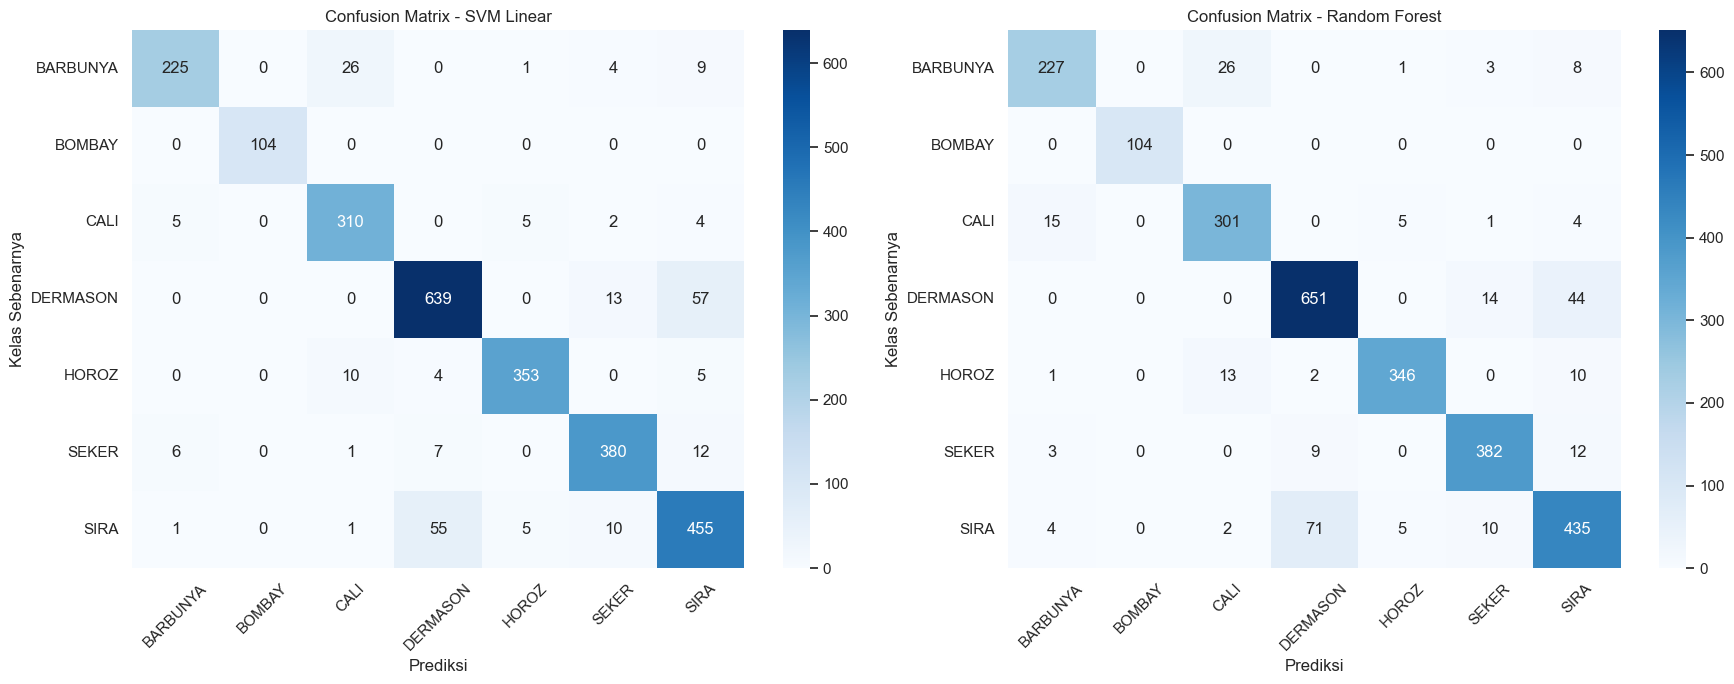

In [58]:
# Confusion matrix untuk kedua model.
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, predictions, model_name in [
    (axes[0], y_pred_svm, 'SVM Linear'),
    (axes[1], y_pred_rf, 'Random Forest')
]:
    cm = confusion_matrix(y_test, predictions, labels=np.arange(len(class_names)))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )
    ax.set_title(f'Confusion Matrix - {model_name}')
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Kelas Sebenarnya')
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

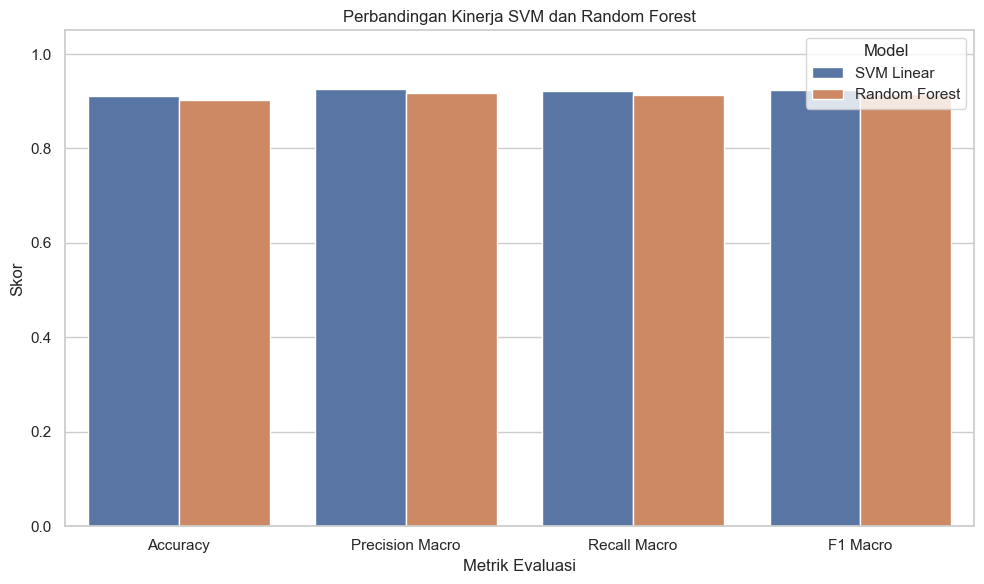

In [59]:
# Membandingkan metrik model dalam grafik.
metrics_to_plot = ['Accuracy', 'Precision Macro', 'Recall Macro', 'F1 Macro']
model_comparison_long = model_comparison.melt(
    id_vars='Model',
    value_vars=metrics_to_plot,
    var_name='Metrik',
    value_name='Skor'
)

plt.figure(figsize=(10, 6))
sns.barplot(data=model_comparison_long, x='Metrik', y='Skor', hue='Model')
plt.ylim(0, 1.05)
plt.title('Perbandingan Kinerja SVM dan Random Forest')
plt.ylabel('Skor')
plt.xlabel('Metrik Evaluasi')
plt.tight_layout()
plt.show()

### 9.1 Interpretasi evaluasi
Gunakan nilai output notebook untuk menjawab:
1. Model mana yang menghasilkan Accuracy tertinggi?
2. Model mana yang menghasilkan Macro F1 tertinggi?
3. Pada varietas apa model paling sering melakukan kesalahan?
4. Apakah terdapat kelas yang memiliki Recall lebih rendah dibandingkan kelas lain?
5. Apakah perbedaan kinerja kedua model cukup besar untuk dianggap berarti dalam konteks proyek?

Jangan menyimpulkan model terbaik hanya dari accuracy. Periksa juga macro F1, classification report, dan confusion matrix.

# 10. Feature Importance Random Forest

Random Forest menyediakan `feature_importances_` untuk menunjukkan kontribusi relatif fitur dalam pemisahan pohon-pohon keputusan. Analisis ini digunakan untuk membantu menjawab fitur morfologi apa yang paling berperan pada model terpilih.

Feature importance adalah ukuran kontribusi model, bukan bukti bahwa suatu fitur menyebabkan jenis kacang tertentu.

,Feature,Importance
0,Perimeter,0.120528
1,ShapeFactor3,0.110993
2,Compactness,0.110215
3,ShapeFactor1,0.087480
4,MajorAxisLength,0.086462
5,MinorAxisLength,0.084040
6,ConvexArea,0.077740
7,Area,0.072974
8,Eccentricity,0.070434
9,AspectRation,0.067497


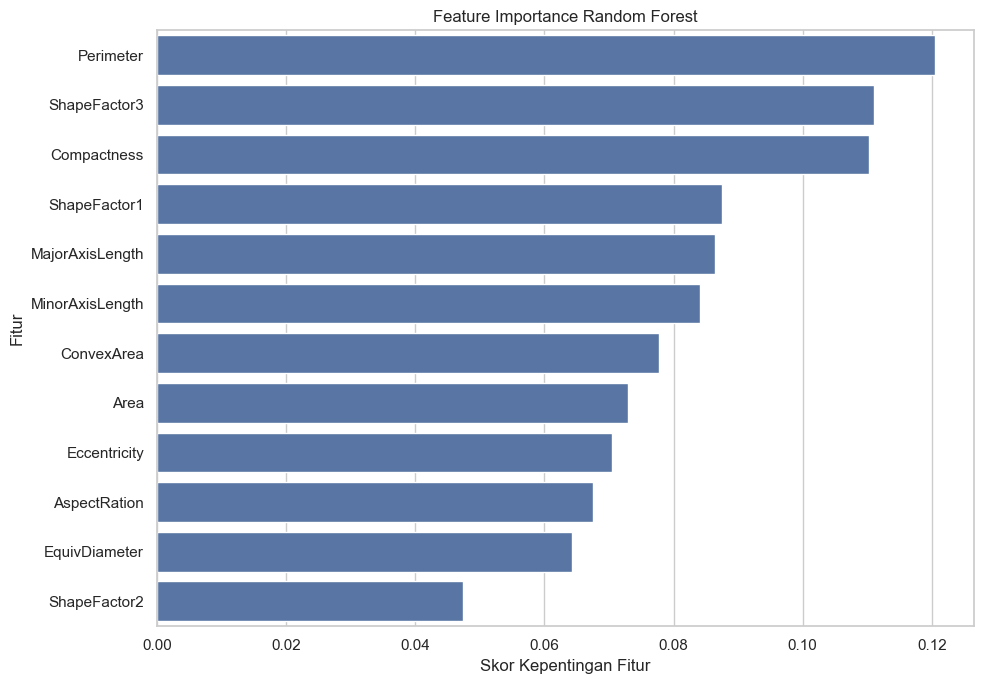

Tiga fitur dengan importance tertinggi:
     Feature  Importance
   Perimeter    0.120528
ShapeFactor3    0.110993
 Compactness    0.110215


In [60]:
rf_classifier = rf_model.named_steps['classifier']
feature_importance_df = pd.DataFrame({
    'Feature': selected_features,
    'Importance': rf_classifier.feature_importances_
}).sort_values('Importance', ascending=False).reset_index(drop=True)

display(feature_importance_df)

plt.figure(figsize=(10, 7))
sns.barplot(data=feature_importance_df, x='Importance', y='Feature')
plt.title('Feature Importance Random Forest')
plt.xlabel('Skor Kepentingan Fitur')
plt.ylabel('Fitur')
plt.tight_layout()
plt.show()

print('Tiga fitur dengan importance tertinggi:')
print(feature_importance_df.head(3).to_string(index=False))

# 11. Analisis Kesalahan Prediksi

Analisis kesalahan membantu melihat apakah model keliru pada pasangan varietas tertentu. Tabel berikut menampilkan contoh prediksi pada data uji dan jumlah kesalahan per pasangan kelas.

In [61]:
# Tentukan model dengan Macro F1 tertinggi sebagai model terbaik.
best_model_name = model_comparison.iloc[0]['Model']
best_predictions = y_pred_svm if best_model_name == 'SVM Linear' else y_pred_rf

prediction_results = pd.DataFrame({
    'Actual': label_encoder.inverse_transform(y_test),
    'Predicted': label_encoder.inverse_transform(best_predictions)
}, index=X_test.index)

misclassified = prediction_results[
    prediction_results['Actual'] != prediction_results['Predicted']
]

print('Model terbaik berdasarkan Macro F1:', best_model_name)
print('Jumlah prediksi salah:', len(misclassified), 'dari', len(prediction_results))
print('\nContoh kesalahan prediksi:')
display(misclassified.head(15))

if len(misclassified) > 0:
    confusion_pairs = (
        misclassified.groupby(['Actual', 'Predicted'])
        .size()
        .sort_values(ascending=False)
        .reset_index(name='Jumlah Kesalahan')
    )
    print('Pasangan kelas yang paling sering tertukar:')
    display(confusion_pairs.head(10))
else:
    print('Tidak ditemukan kesalahan prediksi pada data uji.')

Model terbaik berdasarkan Macro F1: SVM Linear
Jumlah prediksi salah: 243 dari 2709

Contoh kesalahan prediksi:


,Actual,Predicted
1844,SEKER,SIRA
2008,SEKER,SIRA
13514,DERMASON,SIRA
2591,BARBUNYA,CALI
3976,CALI,HOROZ
1812,SEKER,SIRA
8917,SIRA,SEKER
13491,DERMASON,SIRA
2790,BARBUNYA,CALI
8690,SIRA,SEKER


Pasangan kelas yang paling sering tertukar:


,Actual,Predicted,Jumlah Kesalahan
0,DERMASON,SIRA,57
1,SIRA,DERMASON,55
2,BARBUNYA,CALI,26
3,DERMASON,SEKER,13
4,SEKER,SIRA,12
5,HOROZ,CALI,10
6,SIRA,SEKER,10
7,BARBUNYA,SIRA,9
8,SEKER,DERMASON,7
9,SEKER,BARBUNYA,6


# 12. Konklusi

### 12.1 Ringkasan hasil otomatis
Jalankan sel berikut untuk menampilkan ringkasan hasil berdasarkan evaluasi aktual.

In [62]:
best_result = model_comparison.iloc[0]
worst_result = model_comparison.iloc[-1]

print('KESIMPULAN SEMENTARA BERDASARKAN HASIL PENGUJIAN')
print('------------------------------------------------')
print(f"Model terbaik berdasarkan Macro F1: {best_result['Model']}")
print(f"Accuracy       : {best_result['Accuracy']:.4f}")
print(f"Precision Macro: {best_result['Precision Macro']:.4f}")
print(f"Recall Macro   : {best_result['Recall Macro']:.4f}")
print(f"F1 Macro       : {best_result['F1 Macro']:.4f}")
print(f"F1 Weighted    : {best_result['F1 Weighted']:.4f}")
print('\nFitur dengan importance tertinggi pada Random Forest:')
print(', '.join(feature_importance_df.head(3)['Feature'].tolist()))
print('\nJumlah kesalahan model terbaik:', len(misclassified))

KESIMPULAN SEMENTARA BERDASARKAN HASIL PENGUJIAN
------------------------------------------------
Model terbaik berdasarkan Macro F1: SVM Linear
Accuracy       : 0.9103
Precision Macro: 0.9264
Recall Macro   : 0.9214
F1 Macro       : 0.9233
F1 Weighted    : 0.9104

Fitur dengan importance tertinggi pada Random Forest:
Perimeter, ShapeFactor3, Compactness

Jumlah kesalahan model terbaik: 243
